# One quark at a time: the liquefier's frames by jet rapidity and energy

`compare_frames_zjet.ipynb` found that at the LHC the lab frame moves the wake of forward
partons toward midrapidity: by about 0.9 units at $|\eta_d| > 2$, and +19 % in the midrapidity
wake at $\tau = 8$ fm/c. In those events every parton contributes at once: the Z's recoil, ISR
and MPI partons, at all rapidities. This notebook isolates **one jet**: a single quark per
event, at a chosen rapidity $y$ and transverse momentum $p_T$, in the three frames of
`<CausalLiquefier><frame>`:

| frame | the diffusion is solved in | X-SCAPE |
|---|---|---|
| `lab` | the collision's frame (arXiv:2001.08321) | before 2026-11 |
| `bjorken` | the frame of the Bjorken flow at the droplet's $\eta_s$ | the default |
| `fluid` | the rest frame of the background fluid where the droplet was made | new |

**The data** come from `make_gun_data.sh` (this directory):

- one 0–30% Pb+Pb background at 5.02 TeV (`config/PbPb_0_30_ZJet.xml`, seed 102, the Z+jet
  campaign's medium, energy loss and liquefier), reused for every event;
- X-SCAPE's PGun: one u quark per event from the origin ($x = y = z = t = 0$) at $\phi = 0$,
  at $p_T$ = 20, 50, 100 GeV and rapidity $y$ = 0, 1, 2, 3, 4: 15 points, 5 events each;
- in each frame the same 75 events: background, quark, shower and droplets are bit-identical,
  only the deposit differs, so the hydro differences are exact (no sampling noise);
- hadrons: the wake only (bulk jet − background, correlated sampling, 100 samples), no
  fragmentation of the lone quark.

By symmetry $y \ge 0$ is enough. The energy grows forward as $E = p_T \cosh y$: a 20 GeV quark
at $y = 4$ carries 546 GeV.

**Contents.** 1 · The events and their droplets · 2 · Where each deposit lands · 3 · The wake
along $\eta_s$ over time · 4 · Energy, and how much stays in the acceptance · 5 · The
transverse wake · 6 · Hadrons · 7 · Summary

In [1]:
import ast
import os
import sys
import warnings

import hist
import matplotlib.pyplot as plt
import mplhep as hep
import numpy as np

warnings.filterwarnings("ignore", "All-NaN slice")
warnings.filterwarnings("ignore", "invalid value encountered")
sys.path.insert(0, os.getcwd())                 # liquefier_kernel.py, gun_summary.py
import liquefier_kernel as lk

DATA = os.environ.get("LFT_GUN_DATA", os.path.expanduser("~/JetScape/liquefier_gun_test"))
SUMMARY = os.path.join(DATA, "summary.npz")
if not os.path.exists(SUMMARY):
    import gun_summary
    gun_summary.main([DATA])
z = np.load(SUMMARY)
FRAMES = [str(f) for f in z["frames"]]
COL = {"lab": "C3", "bjorken": "C0", "fluid": "C2"}
drops, ev = z["drops"], z["ev"]
E = drops[:, 4]
DC = [str(c) for c in z["dep_columns"]]
dep = {fr: z[f"dep/{fr}"] for fr in ("lab", "bjorken", "fluid")}
col = lambda fr, name: dep[fr][:, DC.index(name)]
P = z["gun_points"]                                   # (K, 2): pT, y
gp, gy, gpt = z["gun_point"].astype(int), z["gun_y"], z["gun_pt"]
PTS, YS = sorted(set(P[:, 0])), sorted(set(P[:, 1]))
kp = lambda pt, y: int(np.nonzero((P[:, 0] == pt) & (P[:, 1] == y))[0][0])
evs = lambda k: np.nonzero(gp == k)[0]
dk = gp[ev]                                           # each droplet's point
etas = z["etas"]
nev = len(z["offsets"]) - 1
NT = max(z[f"{fr}/dE_full"].shape[1] for fr in FRAMES)
tau = z["tau"][0] + (z["tau"][1] - z["tau"][0]) * np.arange(NT)
TAU_DELAY = 1.0

def series(fr, key):
    # (events, NT, ...) of a per-tau summary, NaN where that run stored no frame
    a = z[f"{fr}/{key}"]
    out = np.full((a.shape[0], NT) + a.shape[2:], np.nan)
    out[:, :a.shape[1]] = a
    return out
dEeta = {fr: series(fr, "dE_eta") for fr in FRAMES}
PTM = {pt: m for pt, m in zip(PTS, ("o", "s", "^"))}
print(f"{nev} events, {len(P)} points (pT {PTS} GeV x y {YS}), {len(drops)} droplets, "
      f"{np.abs(E).sum():.0f} GeV (|E|); parID {int(z['gun_parID'])}")
print("checks:", ast.literal_eval(str(z["checks"])))

75 events, 15 points (pT [np.float64(20.0), np.float64(50.0), np.float64(100.0)] GeV x y [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]), 706 droplets, 2785 GeV (|E|); parID 2
checks: {'droplets_identical': True, 'backgrounds_identical': True, 'fluid_from': 'file'}


## 1. The events and their droplets

What one quark leaves in the fluid, per point (means over its 5 events): the number of
droplets, their energy, where in $\eta_s$ and when in $\tau$ they are made. A quark from the
origin moves along $\eta_s = y$ at all times; its shower and the medium partons it kicks (LBT
recoils, and the "holes" they leave, droplets with $E < 0$) spread around it.

pT  y   | droplets | E net [GeV] | E>0 / E<0 [GeV] | mean eta_d - y | median tau_d | made before tau=1
 20   0 |     10.6 |        17.9 |   19.9 /   -2.0 |          +0.10 |         2.85 |     5%
 50   0 |     17.4 |        24.2 |   25.5 /   -1.3 |          -0.01 |         3.20 |    11%
100   0 |     20.0 |        28.1 |   32.5 /   -4.4 |          -0.15 |         2.87 |     7%
 20   1 |      8.8 |        21.8 |   24.6 /   -2.8 |          +0.00 |         2.55 |     7%
 50   1 |     12.8 |        26.8 |   28.4 /   -1.6 |          -0.09 |         2.45 |    12%
100   1 |     20.2 |        49.1 |   54.1 /   -5.1 |          -0.04 |         3.87 |     7%
 20   2 |     10.4 |        45.4 |   48.4 /   -3.0 |          -0.05 |         2.91 |     8%
 50   2 |     10.4 |        42.4 |   47.3 /   -4.9 |          -0.12 |         2.15 |    18%
100   2 |     11.8 |        44.0 |   51.0 /   -7.0 |          -0.10 |         2.18 |    12%
 20   3 |      3.4 |        19.6 |   27.6 /   -8.1 |          -0.04 |

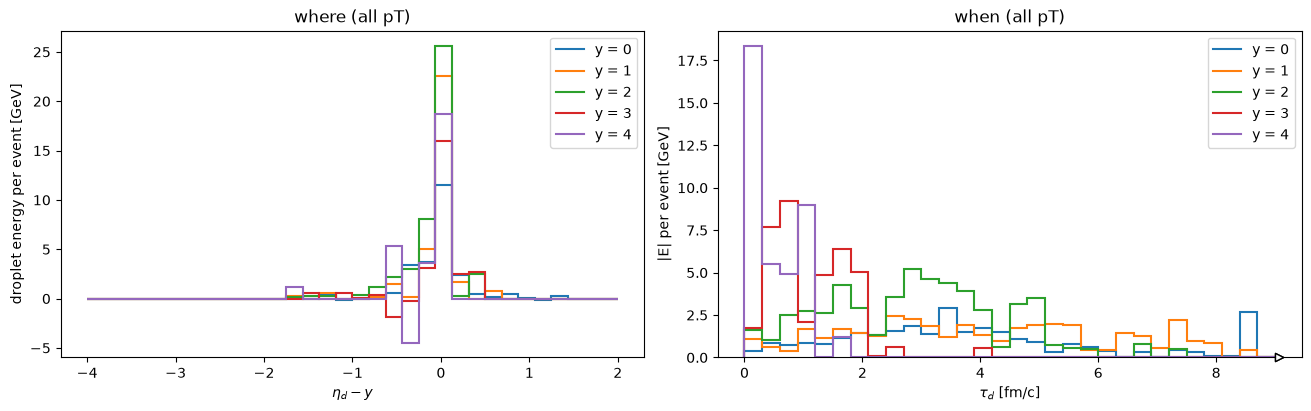

In [2]:
print("pT  y   | droplets | E net [GeV] | E>0 / E<0 [GeV] | mean eta_d - y | median tau_d | made before tau=1")
for y in YS:
    for pt in PTS:
        k = kp(pt, y); m = dk == k; n = len(evs(k))
        w = np.abs(E[m])
        print(f"{pt:3.0f} {y:3.0f} | {m.sum() / n:8.1f} | {E[m].sum() / n:11.1f} | "
              f"{E[m & (E > 0)].sum() / n:6.1f} / {E[m & (E < 0)].sum() / n:6.1f} | "
              f"{np.average(drops[m, 3] - y, weights=w):+14.2f} | {np.median(drops[m, 0]):12.2f} | "
              f"{w[drops[m, 0] < 1].sum() / w.sum():6.0%}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for y in YS:
    m = gy[ev] == y
    h = hist.Hist(hist.axis.Regular(32, -4, 2, name="d", label=r"$\eta_d - y$")).fill(drops[m, 3] - y, weight=E[m])
    hep.histplot(h / len(np.unique(ev[m])), ax=axes[0], label=f"y = {y:g}")
    h = hist.Hist(hist.axis.Regular(30, 0, 9, name="t", label=r"$\tau_d$ [fm/c]")).fill(drops[m, 0], weight=np.abs(E[m]))
    hep.histplot(h / len(np.unique(ev[m])), ax=axes[1], label=f"y = {y:g}")
axes[0].set(ylabel="droplet energy per event [GeV]", title="where (all pT)")
axes[1].set(ylabel="|E| per event [GeV]", title="when (all pT)")
axes[0].legend(); axes[1].legend();

**What to notice.**

- A lone quark leaves little in the fluid: 10–50 GeV net per event, from 3 to 20 droplets. Most of its energy stays in the jet.
- The droplets sit at the quark's rapidity: the mean of $\eta_d - y$ is within 0.3. A few recoils and holes sit about 0.5 below it.
- **When** depends on $y$, because $\tau = t/\cosh y$:
  - at $y \le 2$ the quark deposits from $\tau \approx 1$ to 8 fm/c (median 2–4);
  - at $y = 3$, 40–70 % of its droplets come before $\tau = 1$;
  - at $y = 4$ almost all of them do.
  
  A forward jet crosses the whole medium early in proper time.
- The point $p_T$ = 20 GeV, $y = 4$ deposits only 1.5 GeV per event. Its wake is too small to read, so it is left out of the comparisons below.

## 2. Where each deposit lands

Each droplet's deposit on MUSIC's grid, computed by the Python port of the kernel in all three
frames (`dep/`, `liquefier_kernel.py`): its energy-weighted centroid in $\eta_s$ against the
droplet's own $\eta_d$, the cells it covers, and the share of its energy that lands in cells
MUSIC cannot invert. The lab frame's shift should grow with $\eta_d$ and shrink with the
droplet's age, as $\sim\tau_\text{delay}/\tau_d$.

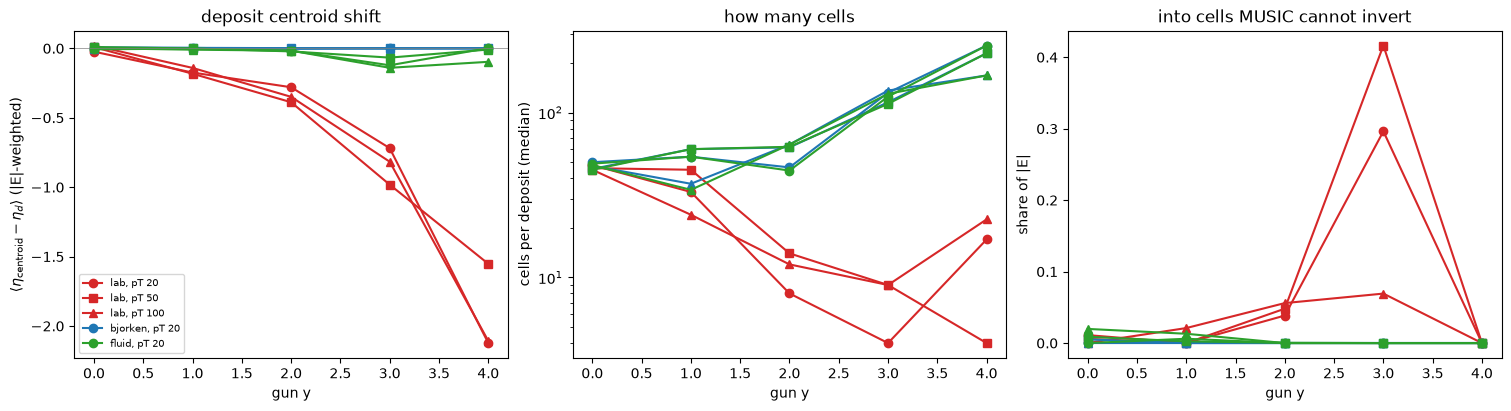

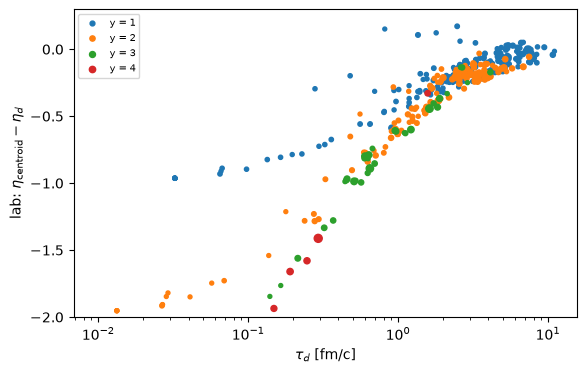

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
rows = []
for fr in FRAMES:
    sh = col(fr, "eta_mean") - drops[:, 3]
    for pt in PTS:
        v, c, b = [], [], []
        for y in YS:
            m = (dk == kp(pt, y)) & np.isfinite(sh)
            w = np.abs(E[m])
            v.append(np.average(sh[m], weights=w))
            c.append(np.nanmedian(col(fr, "cells")[dk == kp(pt, y)]))
            mb = (dk == kp(pt, y)) & np.isfinite(col(fr, "bad_share"))
            b.append(np.sum(col(fr, "bad_share")[mb] * np.abs(E[mb])) / np.abs(E[mb]).sum())
        kw = dict(color=COL[fr], marker=PTM[pt], label=f"{fr}, pT {pt:g}" if fr == "lab" or pt == PTS[0] else None)
        axes[0].plot(YS, v, **kw); axes[1].plot(YS, c, **kw); axes[2].plot(YS, b, **kw)
axes[0].set(xlabel="gun y", ylabel=r"$\langle \eta_\mathrm{centroid} - \eta_d \rangle$ (|E|-weighted)", title="deposit centroid shift")
axes[1].set(xlabel="gun y", ylabel="cells per deposit (median)", yscale="log", title="how many cells")
axes[2].set(xlabel="gun y", ylabel="share of |E|", title="into cells MUSIC cannot invert")
axes[0].axhline(0, color="0.5", lw=0.5); axes[0].legend(fontsize=7)
plt.show()
fig, ax = plt.subplots(figsize=(6.5, 4))
sh = col("lab", "eta_mean") - drops[:, 3]
for y in YS[1:]:
    m = (gy[ev] == y) & np.isfinite(sh)
    ax.scatter(drops[m, 0], sh[m], s=8 + 40 * np.abs(E[m]) / np.abs(E).max(), label=f"y = {y:g}")
ax.set(xscale="log", xlabel=r"$\tau_d$ [fm/c]", ylabel=r"lab: $\eta_\mathrm{centroid} - \eta_d$", ylim=(-2, 0.3))
ax.legend(fontsize=7);

**What to notice.**

- **The lab frame's deposit shift** depends on $y$ and hardly on $p_T$:

  | $y$ | 1 | 2 | 3 | 4 |
  |---|---|---|---|---|
  | shift | −0.15 | −0.3 to −0.4 | −0.7 to −1.0 | −1.5 to −2.1 |

- **It follows the droplet's age** (scatter): about −0.5 at $\tau_d \approx 1$, −1 at 0.3, −1.9 at 0.01 fm/c. It is geometric: the lab-time shell of age $\tau_\text{delay}$ meets the slice $\tau_d + \tau_\text{delay}$ closer to midrapidity the younger and more forward the droplet.
- **The lab frame squeezes forward deposits** into 4–25 cells, against 100–250 in the other frames. At $y = 3$, 30–40 % of the energy of the 20 and 50 GeV quarks lands in cells MUSIC cannot invert.
- **Bjorken and fluid** keep every deposit centred within 0.15 of $\eta_d$.

## 3. The wake along $\eta_s$ over time

The fluid's energy per $\eta_s$ slice, jet leg minus background, summed over each point's 5
events (the ideal part of $T^{\mu\nu}$ through the $\tau$ slice, as in tutorial 06). One row per
$p_T$, one column per gun rapidity; the dotted line is $\eta_s = y$.

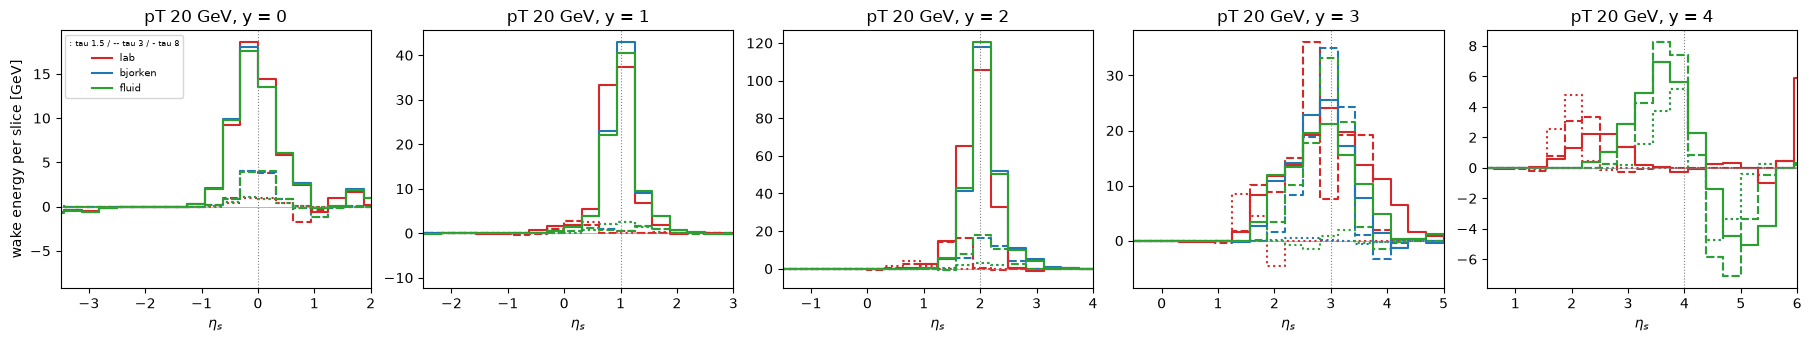

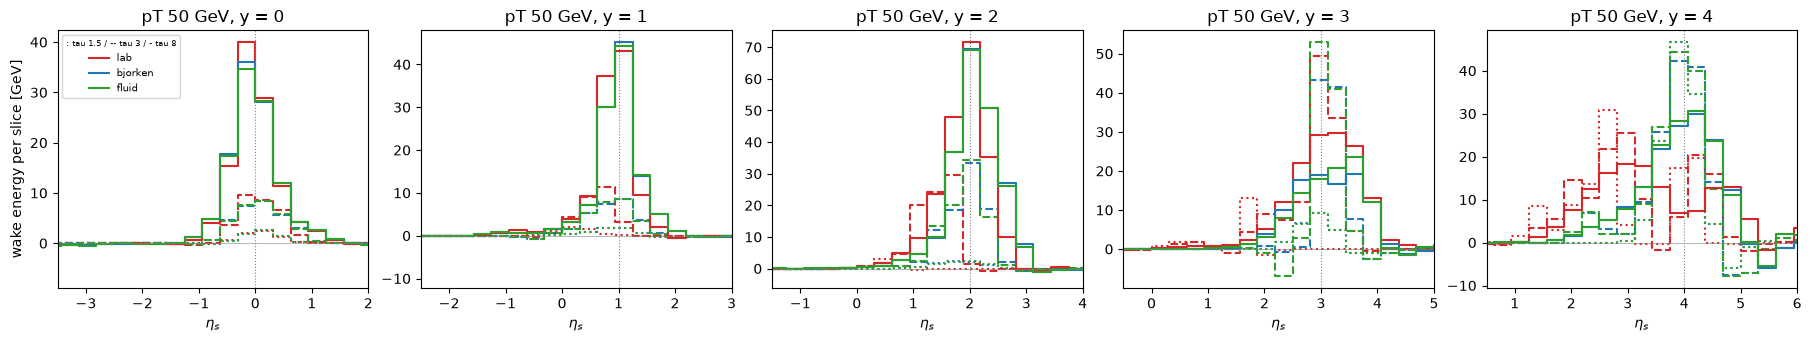

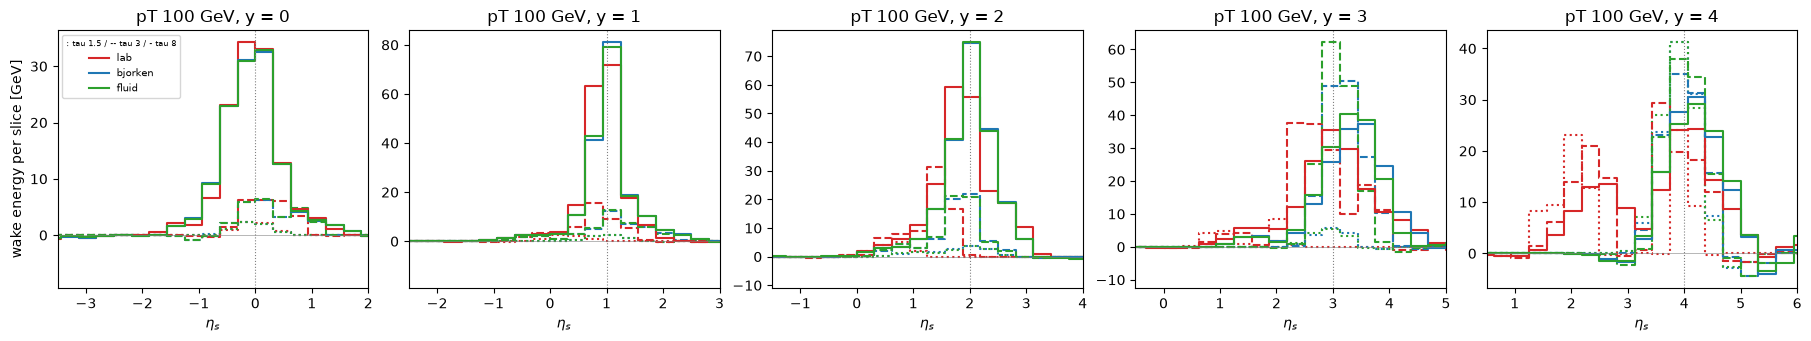

In [4]:
TS = (1.5, 3.0, 8.0)
LS = {1.5: ":", 3.0: "--", 8.0: "-"}
for pt in PTS:
    fig, axes = plt.subplots(1, len(YS), figsize=(18, 3.3), constrained_layout=True)
    for ax, y in zip(axes, YS):
        e = evs(kp(pt, y))
        for t in TS:
            j = int(np.argmin(np.abs(tau - t)))
            for fr in FRAMES:
                ax.step(etas, np.nansum(dEeta[fr][e, j], axis=0), where="mid", color=COL[fr], ls=LS[t],
                        label=f"{fr}" if t == 8.0 else None)
        ax.axvline(y, color="0.5", ls=":", lw=0.8); ax.axhline(0, color="0.5", lw=0.4)
        ax.set(xlim=(y - 3.5, y + 2), title=f"pT {pt:g} GeV, y = {y:g}", xlabel=r"$\eta_s$")
    axes[0].set_ylabel("wake energy per slice [GeV]")
    axes[0].legend(fontsize=7, title=" / ".join(f"{LS[t]} tau {t:g}" for t in TS), title_fontsize=6)
    plt.show()

**What to notice.**

- **$y \le 1$:** the three frames give the same wake.
- **$y = 2$–4, lab frame:** early on ($\tau$ = 1.5, 3) its wake sits 1–2 units below $y$.
- **By $\tau = 8$** most of the lab wake has reached $y$. At $y = 3$–4 a shoulder of misplaced energy remains around $\eta_s \approx 2$–3.
- **Bjorken and fluid** agree along $\eta_s$ at every time.

**One jet's wake over time.** The energy-weighted centroid of each point's wake in $\eta_s$
(within $|\eta_s - y| < 3$), relative to the gun's $y$, against $\tau$; and the lab frame's gap
to the Bjorken frame. Per jet, does the lab frame's misplacement heal as the fluid evolves?

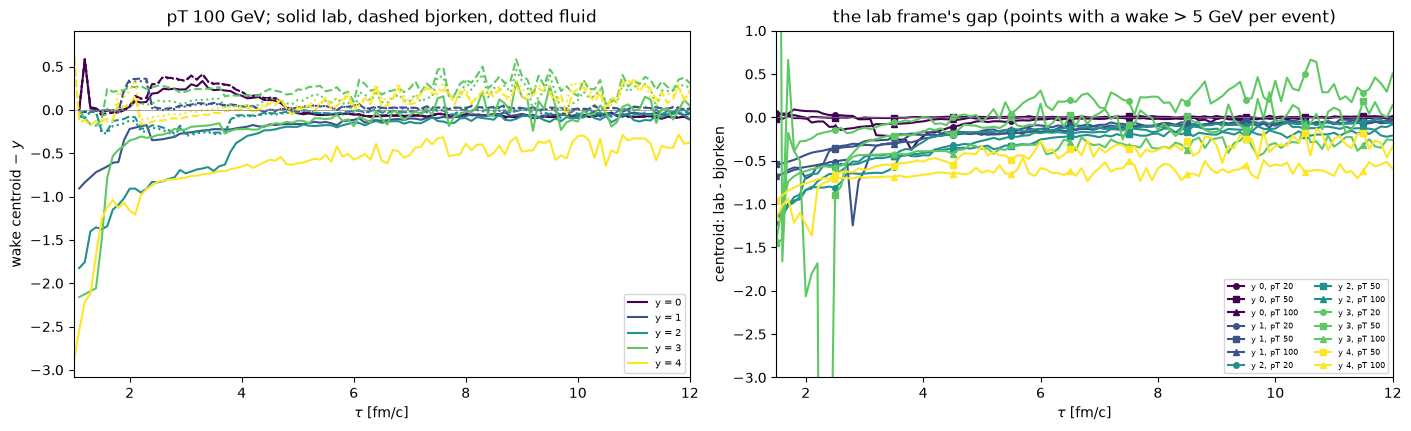

In [5]:
win = lambda y: np.abs(etas - y) < 3.0
def centroid(fr, k):
    p = np.nansum(dEeta[fr][evs(k)], axis=0)            # (NT, eta)
    m = win(P[k, 1])
    return (p[:, m] * etas[m]).sum(axis=1) / p[:, m].sum(axis=1)
C = {fr: np.array([centroid(fr, k) for k in range(len(P))]) for fr in FRAMES}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for k, (pt, y) in enumerate(P):
    if pt != PTS[-1]:
        continue
    c = plt.cm.viridis(y / max(YS))
    for fr, ls in (("lab", "-"), ("bjorken", "--"), ("fluid", ":")):
        axes[0].plot(tau, C[fr][k] - y, color=c, ls=ls, label=f"y = {y:g}" if fr == "lab" else None)
j8 = int(np.argmin(np.abs(tau - 8.0)))
big = [np.nansum(dEeta["bjorken"][evs(k), j8]) / len(evs(k)) > 5.0 for k in range(len(P))]
for k, (pt, y) in enumerate(P):
    if not big[k]:
        continue                                      # a wake under 5 GeV: its centroid is noise
    c = plt.cm.viridis(y / max(YS))
    axes[1].plot(tau, C["lab"][k] - C["bjorken"][k], color=c, marker=PTM[pt], markevery=10, ms=4,
                 label=f"y {y:g}, pT {pt:g}")
axes[0].set(xlabel=r"$\tau$ [fm/c]", ylabel=r"wake centroid $-\ y$", xlim=(1, 12),
            title=f"pT {PTS[-1]:g} GeV; solid lab, dashed bjorken, dotted fluid")
axes[1].set(xlabel=r"$\tau$ [fm/c]", ylabel="centroid: lab - bjorken", xlim=(1.5, 12), ylim=(-3, 1),
            title="the lab frame's gap (points with a wake > 5 GeV per event)")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=6, ncol=2)
for a in axes: a.axhline(0, color="0.5", lw=0.5)

**What to notice.**

Per jet, the lab frame's offset shrinks fast in the first few fm/c, then freezes. The offset of the wake centroid relative to bjorken (lab − bjorken):

| $y$ | $\tau \approx 2$ | $\tau = 8$ |
|---|---|---|
| 1 | −0.4 to −0.7 | −0.1 |
| 2 | −0.7 to −0.8 | −0.1 to −0.2 |
| 3 | −0.6 to −2 | −0.15 to −0.36 |
| 4 | −0.8 to −1.2 | −0.4 to −0.6 |

From $\tau \approx 4$ on the curves are flat: what is left reaches freeze-out. Two mechanisms do the early shrinking:

1. **The jet's own later droplets.** The shift goes as $1/\tau_d$, so these land closer to $y$ and dilute the early, most displaced ones. This is the larger part. At $y = 4$, the gap goes from −2.8 to −0.8 between $\tau$ = 1 and 2, as the droplets made up to $\tau_d \approx 1$ arrive.
2. **Drift.** A misplaced deposit keeps its droplet's forward momentum, and the fluid carries it outward. At $y = 4$ no droplet arrives after $\tau \approx 2.5$, and the gap still closes from −0.8 to −0.5.

The centroid understates the distortion: the lab profile at $y = 3$–4 is double-humped. The energy in the acceptance (section 4) is the robust measure.

The fluid frame stays within 0.05 of bjorken after $\tau \approx 3$.

## 4. Energy, and how much stays in the acceptance

**Bookkeeping.** The fluid's energy gain over the whole grid against the energy deposited so
far (droplets with $\tau_d + \tau_\text{delay} \le \tau$), per point and frame: a lost deposit
(MUSIC reverting a cell it cannot invert) shows as a ratio below 1.

**Acceptance.** The share of each point's wake inside $|\eta_s| < 2.4$ (the CMS tracker's
$|\eta|$ range, to the extent that $\eta \approx \eta_s$ for the wake's hadrons) at
$\tau = 8$ fm/c, lab and fluid against bjorken: how much of a forward jet's wake the lab frame
pulls into the acceptance.

/var/folders/j2/h010kgbj407bhm464v8g5q8m0000gq/T/ipykernel_84486/2007201223.py:6: RuntimeWarning: divide by zero encountered in divide
  r = np.nansum(series(fr, "dE_full")[e], axis=0) / dep_t[e].sum(axis=0)


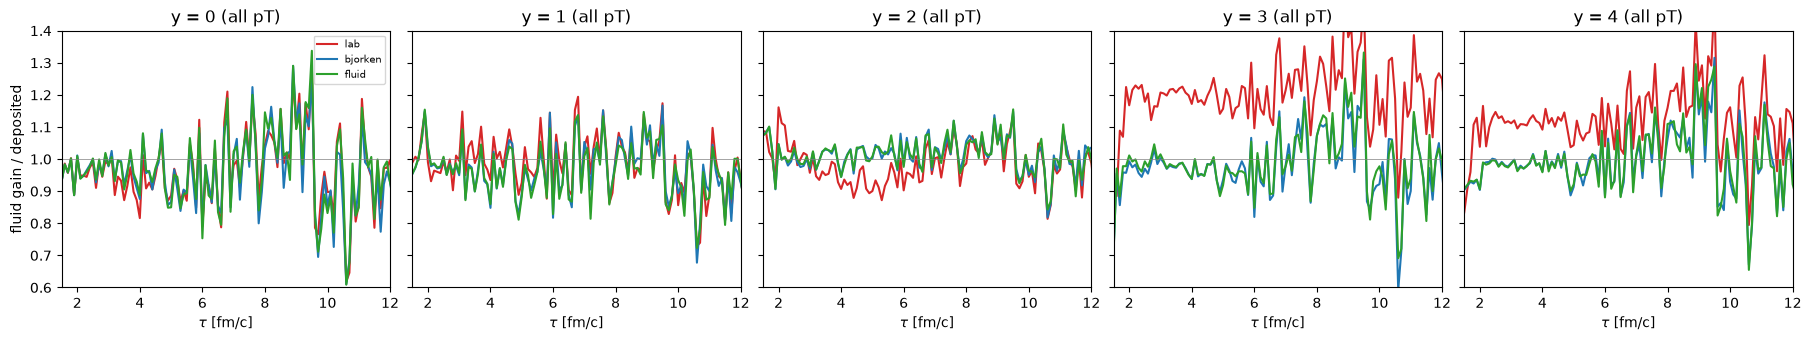

pT  y  | wake at tau 8 [GeV/event] lab / bjorken / fluid | in |eta_s|<2.4: lab / bjorken / fluid | lab - bj, fluid - bj [GeV] (% of the jet's wake)
 20  0 |    11.3 /    11.5 /    13.7 |    10.9 /    11.0 /    10.9 |   -0.1 ( -1%),   -0.1 ( -1%)
 50  0 |    22.7 /    23.8 /    25.0 |    21.4 /    21.4 /    21.2 |   -0.0 ( -0%),   -0.2 ( -1%)
100  0 |    26.4 /    24.5 /    27.6 |    24.6 /    24.4 /    24.5 |   +0.1 ( +1%),   +0.0 ( +0%)
 20  1 |    18.7 /    17.3 /    16.3 |    17.5 /    17.1 /    16.5 |   +0.4 ( +2%),   -0.6 ( -3%)
 50  1 |    22.9 /    22.6 /    23.9 |    21.8 /    21.9 /    21.8 |   -0.1 ( -0%),   -0.1 ( -0%)
100  1 |    37.0 /    37.8 /    36.2 |    37.3 /    35.9 /    35.8 |   +1.4 ( +4%),   -0.1 ( -0%)
 20  2 |    43.9 /    47.9 /    49.1 |    44.2 /    43.2 /    43.8 |   +0.9 ( +2%),   +0.5 ( +1%)
 50  2 |    41.4 /    44.3 /    42.2 |    39.0 /    35.2 /    35.1 |   +3.8 ( +9%),   -0.1 ( -0%)
100  2 |    43.3 /    45.5 /    44.9 |    37.3 /    38.1 /    38.2 |

In [6]:
dep_t = np.array([[E[(ev == i) & (drops[:, 0] + TAU_DELAY <= t)].sum() for t in tau] for i in range(nev)])
fig, axes = plt.subplots(1, len(YS), figsize=(18, 3.3), constrained_layout=True, sharey=True)
for ax, y in zip(axes, YS):
    e = np.nonzero(gy == y)[0]                       # the three pT together: 15 events
    for fr in FRAMES:
        r = np.nansum(series(fr, "dE_full")[e], axis=0) / dep_t[e].sum(axis=0)
        ax.plot(tau, r, color=COL[fr], label=fr)
    ax.axhline(1, color="0.5", lw=0.5)
    ax.set(xlim=(1.5, 12), ylim=(0.6, 1.4), title=f"y = {y:g} (all pT)", xlabel=r"$\tau$ [fm/c]")
axes[0].set_ylabel("fluid gain / deposited"); axes[0].legend(fontsize=7)
plt.show()
j8 = int(np.argmin(np.abs(tau - 8.0)))
acc = np.abs(etas) < 2.4
print("pT  y  | wake at tau 8 [GeV/event] lab / bjorken / fluid | in |eta_s|<2.4: lab / bjorken / fluid | lab - bj, fluid - bj [GeV] (% of the jet's wake)")
for y in YS:
    for pt in PTS:
        e = evs(kp(pt, y)); n = len(e)
        tot = {fr: np.nansum(dEeta[fr][e, j8]) / n for fr in FRAMES}
        ina = {fr: np.nansum(dEeta[fr][e, j8][:, acc]) / n for fr in FRAMES}
        print(f"{pt:3.0f} {y:2.0f} | {tot['lab']:7.1f} / {tot['bjorken']:7.1f} / {tot['fluid']:7.1f} | "
              f"{ina['lab']:7.1f} / {ina['bjorken']:7.1f} / {ina['fluid']:7.1f} | "
              f"{ina['lab'] - ina['bjorken']:+6.1f} ({(ina['lab'] - ina['bjorken']) / tot['bjorken']:+4.0%}), "
              f"{ina['fluid'] - ina['bjorken']:+6.1f} ({(ina['fluid'] - ina['bjorken']) / tot['bjorken']:+4.0%})")

**What to notice.**

- **Bookkeeping.** At $y = 0$–2 all frames follow the deposits: the ratio to the energy deposited is about 1, with the same ±10 % numerical noise in every frame (a small wake on a large grid). In the lab frame the forward points come out off 1:
  - at $y$ = 3 and 4 the fluid *gains* 10–20 % more than was deposited: the uninvertible cells discard negative droplets (holes, up to −15 GeV per event here) more than positive ones;
  - at $y = 2$ it loses up to 10 % around $\tau$ = 3–6.
- **Acceptance.** The lab frame puts energy inside $|\eta_s| < 2.4$ that belongs outside. Per event, at $\tau = 8$:

  | $y$ | lab − bjorken | share of the jet's wake |
  |---|---|---|
  | 3 | +1.4 to +3.7 GeV | 6–11 % |
  | 4 | +3.7 to +4.8 GeV | 13–23 % |

  At $y = 4$ the Bjorken frame puts almost nothing in the acceptance.
- **$y \le 2$:** within 2 %, except $p_T$ = 50, $y = 2$, at +9 % (wake moved across the edge at 2.4).
- **The fluid frame** is within ±3 % of bjorken everywhere.
- What enters the acceptance is the leftover of section 3: the misplaced shoulder of forward jets.

## 5. The transverse wake

The wake's energy density at $\tau$ = 3 and 6 fm/c summed over $|\eta_s - y| < 0.5$ (the slice
of the gun), for the strongest quark ($p_T$ = 100 GeV) at $y$ = 0 and 3. The quark moves along
$+x$. The fluid frame boosts each deposit into the fluid's rest frame: carried with the radial
flow and contracted along it.

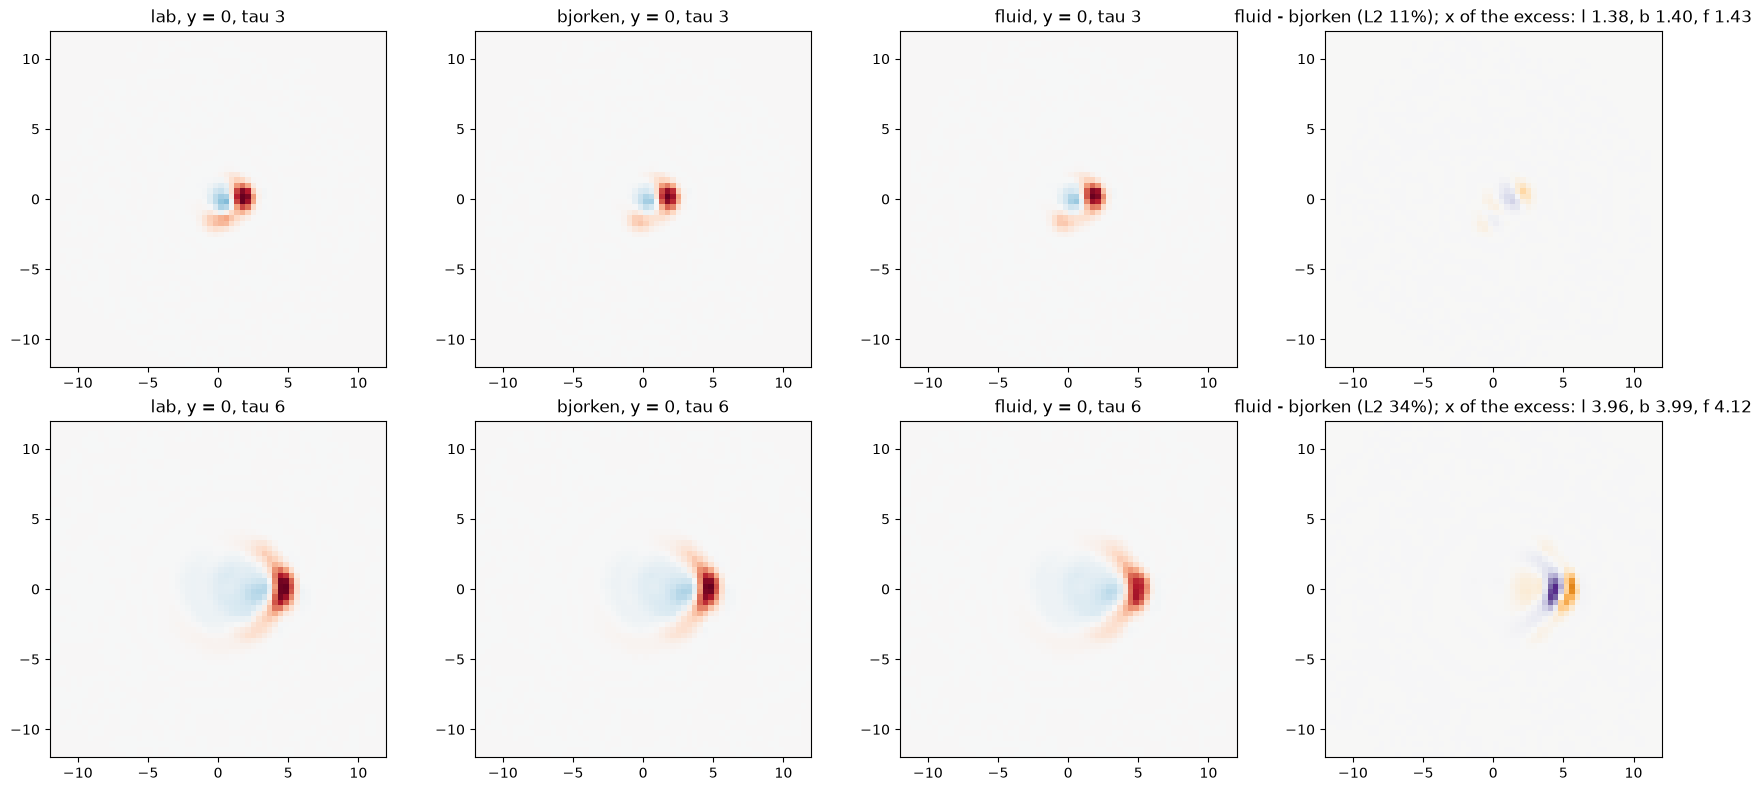

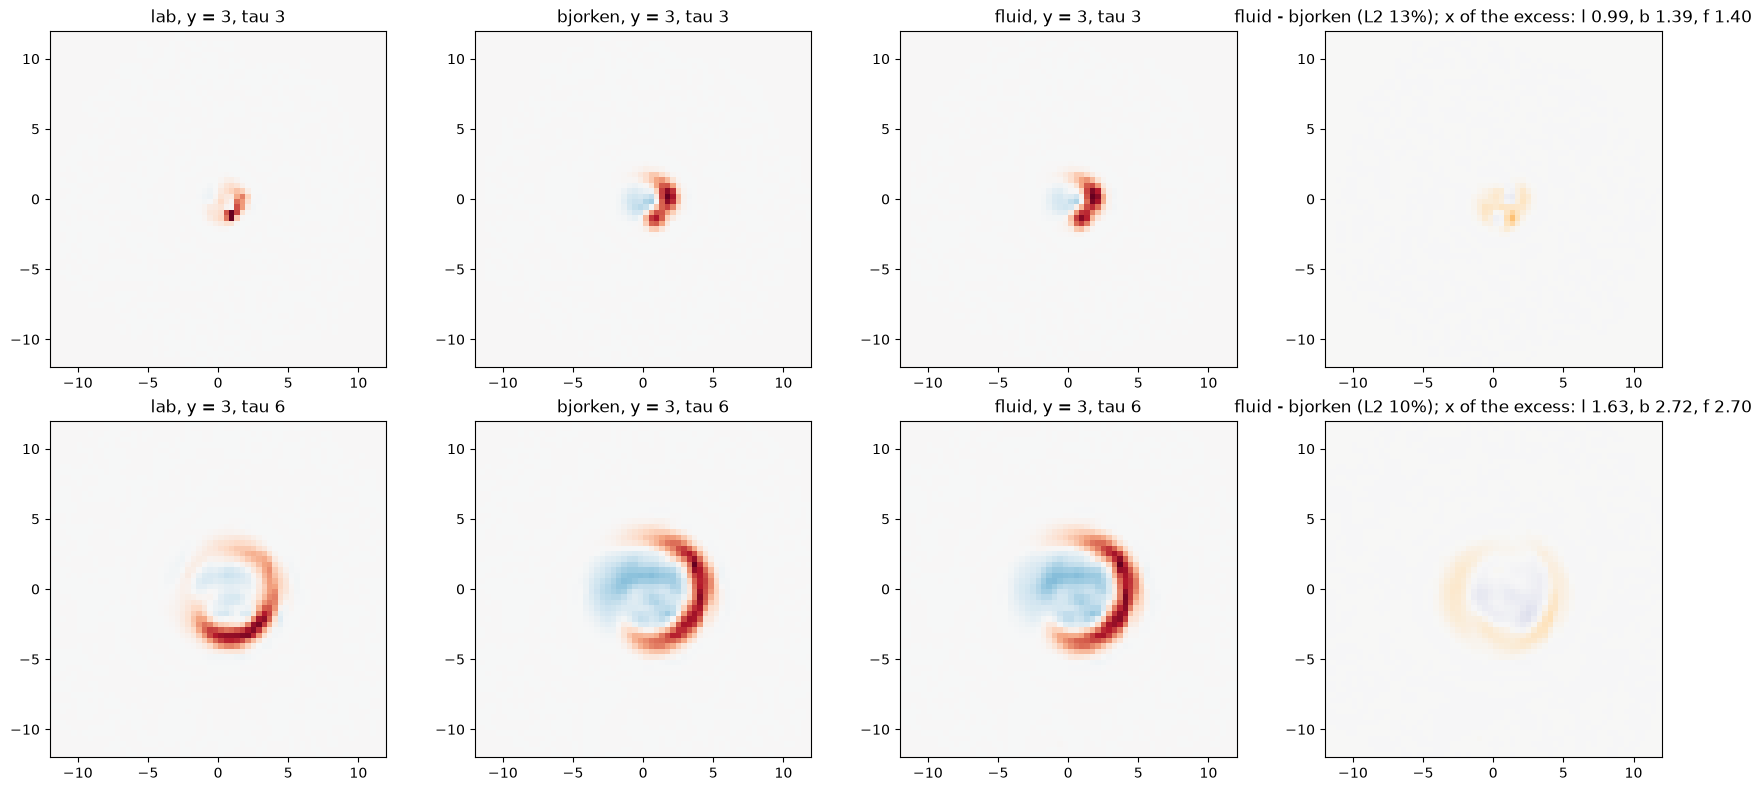

In [7]:
X, Y = z["x"], z["y"]
MT = [float(t) for t in z["map_taus"]]
for y in (YS[0], YS[min(3, len(YS) - 1)]):
    e = evs(kp(PTS[-1], y))
    fig, axes = plt.subplots(len(MT), 4, figsize=(17, 3.9 * len(MT)), constrained_layout=True)
    for r, t in enumerate(MT):
        maps = {fr: np.nansum(z[f"{fr}/map"][e, r], axis=0) for fr in FRAMES}
        vmax = np.nanmax(np.abs(maps["bjorken"]))
        for c, fr in enumerate(FRAMES):
            axes[r, c].pcolormesh(X, Y, maps[fr].T, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
            axes[r, c].set(title=f"{fr}, y = {y:g}, tau {t:g}", xlim=(-12, 12), ylim=(-12, 12), aspect="equal")
        d = maps["fluid"] - maps["bjorken"]
        axes[r, 3].pcolormesh(X, Y, d.T, cmap="PuOr_r", vmin=-vmax / 2, vmax=vmax / 2)
        l2 = np.sqrt((d ** 2).sum() / (maps["bjorken"] ** 2).sum())
        pos = {fr: np.clip(maps[fr], 0, None) for fr in FRAMES}
        xc = {fr: (pos[fr].sum(axis=1) * X).sum() / pos[fr].sum() for fr in FRAMES}
        axes[r, 3].set(title=f"fluid - bjorken (L2 {l2:.0%}); x of the excess: " + ", ".join(f"{fr[0]} {xc[fr]:.2f}" for fr in FRAMES),
                       xlim=(-12, 12), ylim=(-12, 12), aspect="equal")
    plt.show()

**What to notice.**

- **Lab vs bjorken** transversally: the same at $y = 0$. At $y = 3$ the lab frame's slice holds less of the wake: part of it sits at lower $\eta_s$.
- **Fluid vs bjorken:** a dipole along the flow. The fluid frame carries each deposit outward with the radial flow and contracts it. The wake front moves out by about 0.4 fm.
  - L2 differences: 11 % at $\tau = 3$ and 34 % at $\tau = 6$ for $y = 0$; 10–13 % at $y = 3$.
  - This is the size seen in Au+Au (18–30 %).

## 6. Hadrons

The charged wake hadrons (bulk jet − background, correlated sampling, 100 samples; no jet
fragments) per event, per point. Each frame hadronized its own samples, so a frame difference
carries the two frames' errors in quadrature.

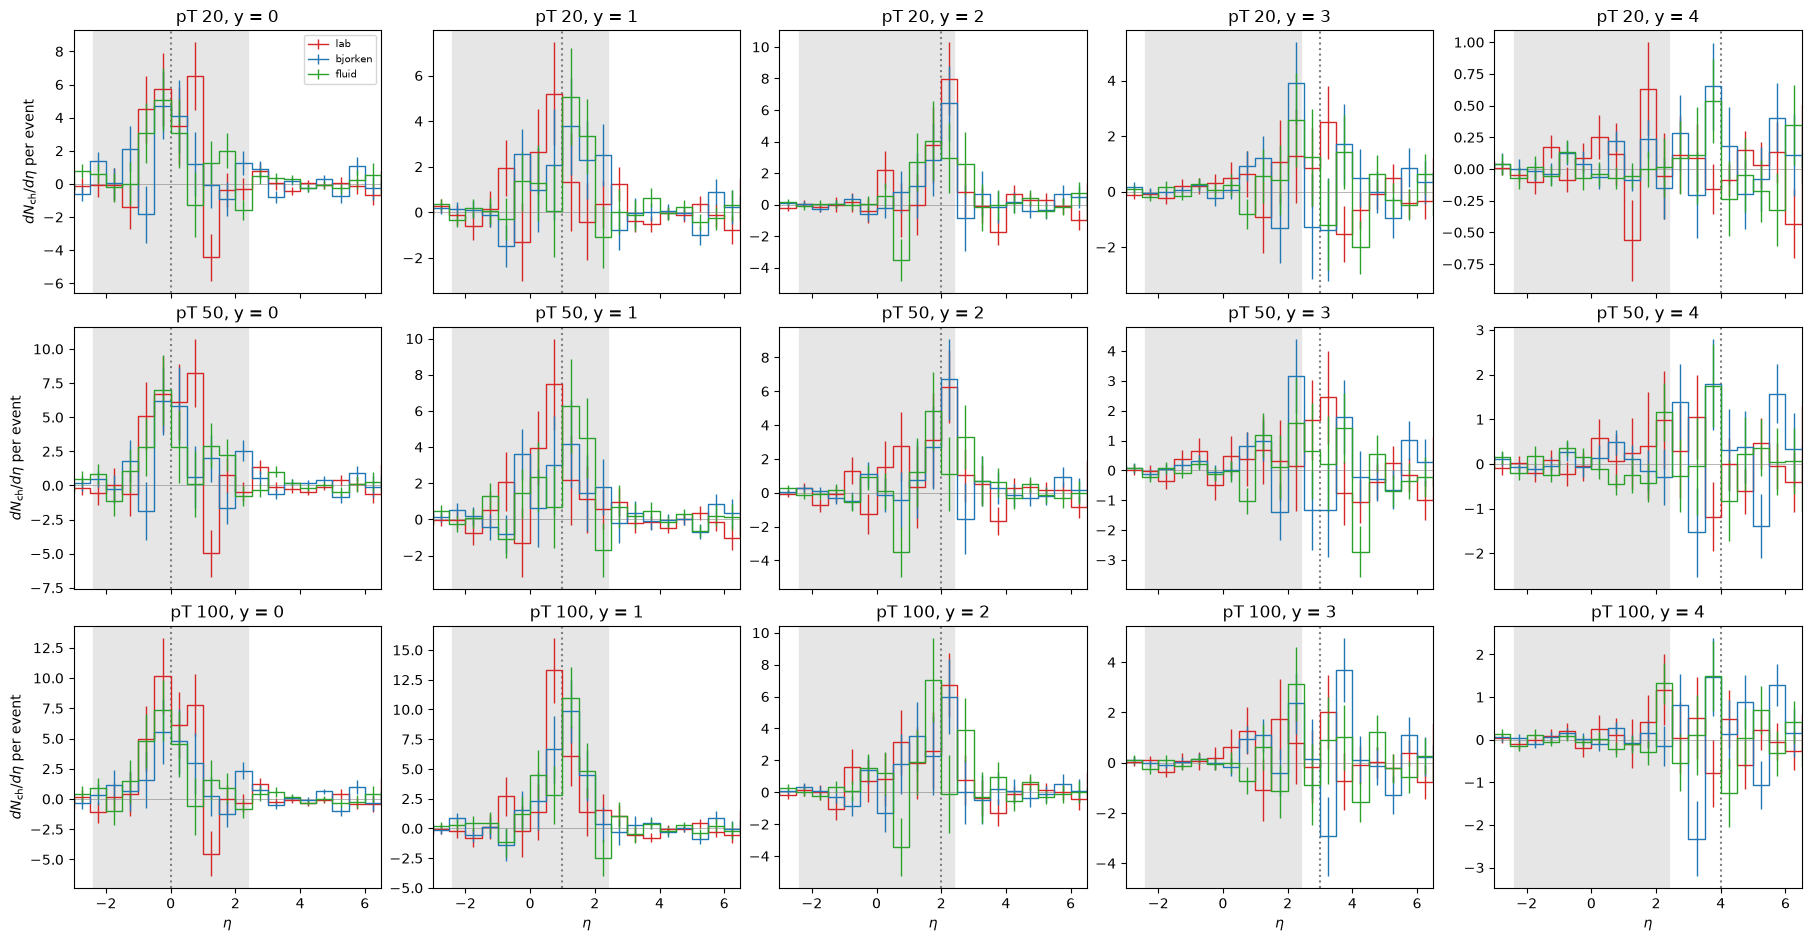

pT  y  | N |eta-y|<1 bjorken | lab - bj | fluid - bj || N |eta|<2.4 bjorken | lab - bj | fluid - bj
 20  0 |   4.09 +- 1.25 |  +6.03 +- 2.02 (+3.0 sig) |  +0.90 +- 1.83 (+0.5 sig) ||   5.89 +- 1.47 |  +0.91 +- 2.15 (+0.4 sig) |  +0.36 +- 1.94 (+0.2 sig)
 50  0 |   5.40 +- 1.56 |  +7.69 +- 2.69 (+2.9 sig) |  +0.98 +- 2.33 (+0.4 sig) ||   8.11 +- 1.73 |  +2.04 +- 2.75 (+0.7 sig) |  +0.92 +- 2.44 (+0.4 sig)
100  0 |   7.40 +- 1.73 |  +7.11 +- 2.87 (+2.5 sig) |  +0.63 +- 2.49 (+0.3 sig) ||   9.56 +- 2.03 |  +2.03 +- 3.00 (+0.7 sig) |  +0.03 +- 2.68 (+0.0 sig)
 20  1 |   4.56 +- 1.37 |  -0.17 +- 2.01 (-0.1 sig) |  +0.32 +- 1.94 (+0.2 sig) ||   6.62 +- 1.41 |  -2.13 +- 2.08 (-1.0 sig) |  -1.74 +- 1.93 (-0.9 sig)
 50  1 |   4.61 +- 1.54 |  +2.72 +- 2.22 (+1.2 sig) |  +2.30 +- 2.13 (+1.1 sig) ||   7.31 +- 1.44 |  -0.03 +- 2.20 (-0.0 sig) |  -0.29 +- 2.01 (-0.1 sig)
100  1 |  11.60 +- 1.75 |  -0.53 +- 2.59 (-0.2 sig) |  -0.01 +- 2.42 (-0.0 sig) ||  12.78 +- 1.73 |  -0.55 +- 2.68 (-0.2 sig) |  -

In [8]:
he = z["hg_eta_edges"]; hc = 0.5 * (he[1:] + he[:-1])
fig, axes = plt.subplots(len(PTS), len(YS), figsize=(18, 3.1 * len(PTS)), constrained_layout=True, sharex="col")
for r, pt in enumerate(PTS):
    for c, y in enumerate(YS):
        ax = axes[r, c]; k = kp(pt, y)
        for fr in FRAMES:
            v, er = z[f"{fr}/hg_dndeta"][k]
            ax.errorbar(hc, v / np.diff(he), er / np.diff(he), color=COL[fr], ds="steps-mid", lw=1, label=fr)
        ax.axvline(y, color="0.5", ls=":"); ax.axhline(0, color="0.5", lw=0.4)
        ax.axvspan(-2.4, 2.4, color="0.9", zorder=-1)
        ax.set(title=f"pT {pt:g}, y = {y:g}", xlim=(-3, 6.5))
        if c == 0: ax.set_ylabel(r"$dN_\mathrm{ch}/d\eta$ per event")
        if r == len(PTS) - 1: ax.set_xlabel(r"$\eta$")
axes[0, 0].legend(fontsize=7)
plt.show()
TC = [str(c) for c in z["hg_tot_columns"]]
def diff(q, k, fr):
    a, b = z[f"{fr}/hg_tot"][k, TC.index(q)], z[f"bjorken/hg_tot"][k, TC.index(q)]
    d, s = a[0] - b[0], np.hypot(a[1], b[1])
    return f"{d:+6.2f} +- {s:4.2f} ({d / s:+4.1f} sig)"
print("pT  y  | N |eta-y|<1 bjorken | lab - bj | fluid - bj || N |eta|<2.4 bjorken | lab - bj | fluid - bj")
for y in YS:
    for pt in PTS:
        k = kp(pt, y); b = z["bjorken/hg_tot"][k]
        print(f"{pt:3.0f} {y:2.0f} | {b[0, 0]:6.2f} +- {b[0, 1]:4.2f} | {diff('N |eta-y|<1', k, 'lab')} | "
              f"{diff('N |eta-y|<1', k, 'fluid')} || {b[2, 0]:6.2f} +- {b[2, 1]:4.2f} | "
              f"{diff('N |eta|<2.4', k, 'lab')} | {diff('N |eta|<2.4', k, 'fluid')}")

**What to notice.**

- **Errors.** At hadron level the per-point errors are 1–3 charged hadrons per event, on wakes of 1–12. No frame difference is significant.
- **The +3σ at $y = 0$ is a sampling artefact.** The lab frame's $|\eta - y| < 1$ excess appears at all three $p_T$ with the same bin-by-bin pattern, a spike at $\eta \approx 0.75$ and a dip at 1.25. At $y = 0$ the hydro of the frames is identical.
  - All 75 events of a frame share one background and its cell-addressed random numbers (correlated sampling, common seeds).
  - So their sampling noise repeats from event to event and point to point.
  - The points are therefore not independent tests.
- **What the hydro predicts here is too small to see.** The lab frame's extra +1.4 to +4.8 GeV in the acceptance at $y$ = 3–4 is lab energy at $\eta_s \approx 2$, mostly longitudinal. It is worth about 1–2 charged hadrons per event, below the ±1–1.2 error. The measured −0.8 to −1.5 is within about 1.3σ of zero.

## 7. Summary

Per point: the lab frame's deposit shift, the wake centroid's gap to the Bjorken frame at
$\tau$ = 2 and 8 fm/c (lab and fluid), the wake energy inside $|\eta_s| < 2.4$ at $\tau = 8$
relative to bjorken, and the charged wake hadrons in $|\eta| < 2.4$ (lab − bjorken, in units of
its error).

In [9]:
j2 = int(np.argmin(np.abs(tau - 2.0)))
sh = col("lab", "eta_mean") - drops[:, 3]
head = ("pT", "y", "E [GeV]", "wake tau 8 [GeV]", "lab deposit shift", "gap lab tau 2 / 8",
        "gap fluid tau 2 / 8", "in |eta_s|<2.4: lab - bj [GeV]", "N_ch |eta|<2.4 lab - bj")
print(" | ".join(head)); print(" | ".join("---" for _ in head))
for y in YS:
    for pt in PTS:
        k = kp(pt, y); e = evs(k); m = (dk == k) & np.isfinite(sh)
        ina = {fr: np.nansum(dEeta[fr][e, j8][:, acc]) for fr in FRAMES}
        a, b = z["lab/hg_tot"][k, 2], z["bjorken/hg_tot"][k, 2]
        wt = np.nansum(dEeta["bjorken"][e, j8]) / len(e)
        print(" | ".join([f"{pt:g}", f"{y:g}", f"{pt * np.cosh(y):.0f}",
                          f"{wt:.1f}" + (" (too small)" if wt < 5 else ""),
                          f"{np.average(sh[m], weights=np.abs(E[m])):+.2f}",
                          f"{C['lab'][k][j2] - C['bjorken'][k][j2]:+.2f} / {C['lab'][k][j8] - C['bjorken'][k][j8]:+.2f}",
                          f"{C['fluid'][k][j2] - C['bjorken'][k][j2]:+.2f} / {C['fluid'][k][j8] - C['bjorken'][k][j8]:+.2f}",
                          f"{(ina['lab'] - ina['bjorken']) / len(e):+.1f} ({(ina['lab'] - ina['bjorken']) / len(e) / wt:+.0%})",
                          f"{a[0] - b[0]:+.2f} ({(a[0] - b[0]) / np.hypot(a[1], b[1]):+.1f} sig)"]))

pT | y | E [GeV] | wake tau 8 [GeV] | lab deposit shift | gap lab tau 2 / 8 | gap fluid tau 2 / 8 | in |eta_s|<2.4: lab - bj [GeV] | N_ch |eta|<2.4 lab - bj
--- | --- | --- | --- | --- | --- | --- | --- | ---
20 | 0 | 20 | 11.5 | -0.02 | +0.07 / -0.02 | +0.01 / -0.00 | -0.1 (-1%) | +0.91 (+0.4 sig)
50 | 0 | 50 | 23.8 | +0.01 | -0.01 / +0.01 | +0.00 / +0.01 | -0.0 (-0%) | +2.04 (+0.7 sig)
100 | 0 | 100 | 24.5 | +0.02 | -0.00 / -0.00 | +0.00 / -0.01 | +0.1 (+1%) | +2.03 (+0.7 sig)
20 | 1 | 31 | 17.3 | -0.17 | -0.71 / -0.10 | +0.01 / +0.01 | +0.4 (+2%) | -2.13 (-1.0 sig)
50 | 1 | 77 | 22.6 | -0.18 | -0.43 / -0.08 | -0.03 / +0.00 | -0.1 (-0%) | -0.03 (-0.0 sig)
100 | 1 | 154 | 37.8 | -0.14 | -0.57 / -0.09 | -0.03 / -0.01 | +1.4 (+4%) | -0.55 (-0.2 sig)
20 | 2 | 75 | 47.9 | -0.28 | -0.84 / -0.16 | -0.06 / -0.01 | +0.9 (+2%) | +0.05 (+0.0 sig)
50 | 2 | 188 | 44.3 | -0.39 | -0.67 / -0.19 | -0.04 / -0.01 | +3.8 (+9%) | +0.07 (+0.0 sig)
100 | 2 | 376 | 45.5 | -0.35 | -0.84 / -0.09 | -0.05 / -0.

**Summary.**

For one jet the lab frame's error is set by the jet's rapidity, hardly by its energy:

| $y$ | deposit shift | wake offset, $\tau \approx 2$ | wake offset, $\tau = 8$ | lab − bjorken in $\|\eta_s\| < 2.4$ |
|---|---|---|---|---|
| 1 | −0.15 | −0.4 to −0.7 | −0.1 | ≈ 0 |
| 2 | −0.3 to −0.4 | −0.7 to −0.8 | −0.1 to −0.2 | ≈ 0 |
| 3 | −0.7 to −1.0 | up to −2 | −0.15 to −0.36 | 6–11 % of the wake |
| 4 | −1.5 to −2.1 | −0.8 to −1.2 | −0.4 to −0.6 | 13–23 % of the wake |

- **Per jet the wake partly heals.** Its own later droplets are less displaced, and the misplaced energy drifts outward with its momentum. From $\tau \approx 4$ on, what is left stays to freeze-out.
- **What stays is a misplaced lump.** For forward jets it lands inside the acceptance.
- **Fluid frame:** the same as bjorken along $\eta_s$ (gap < 0.05, acceptance ±3 %), with its transverse dipole as in Au+Au.
- **Hadrons:** with 5 events and 100 samples per point they cannot resolve any of this.